# 02 · Segmentación: modelos, HPO y evaluación con inferencia estadística

**Entrada:** `reports/tables/seg_eval_test.csv` (métricas por imagen de cada modelo y semilla en el test
sellado). Ese archivo lo genera `scripts/seg_experiments.py evaluate ...` para los seis paradigmas,
todos con el mismo código de evaluación (`project.adapters_seg.evaluate_adapter`).

| Pos | Modelo | Implementación | Comando |
|---|---|---|---|
| 0 | Otsu/adaptativo + watershed | propia (`classical.py`) | `evaluate --model classical` |
| 1 | Mask R-CNN + Swin | MMDetection (config en `configs/seg_maskrcnn.yaml`) | `evaluate --model maskrcnn_mmdet:cfg,ckpt` |
| 2 | Hover-Net (NP + HV) | repo oficial + post-proceso propio | `evaluate --model hovernet:mod:fn` |
| 3 | U-Net++ + watershed | **propia en Keras** (`models_seg.py`) | `train` + `evaluate --model unetpp:ruta` |
| 4 | Cellpose 2.0 (generalista / ajustado) | `cellpose` 3.x | `evaluate --model cellpose:cyto2` |
| 5 | SAM / MedSAM (cero-shot, cajas, LoRA) | `segment-anything` | `evaluate --model sam_auto:ckpt` |

> **Modo demo.** Si el CSV no existe, el notebook evalúa en datos sintéticos el baseline clásico y dos
> variantes declaradas (umbral adaptativo y `min_distance` = 8). Así se ejercita **todo** el pipeline
> estadístico, pero esas cifras no son resultados del proyecto.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings

import yaml

from project.config import CFG, set_global_seed
from project.reporting import (add_terciles, best_worst, error_profile, pairwise_report, ranking_agreement,
                               results_table, simpson_check, stratified)
from project.seg_metrics import THRESHOLDS
from project.stats import bootstrap_ci, fmt_ci, mixed_model_check, plot_cd_diagram

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*constant.*")
set_global_seed(CFG.seed)
ROOT = Path("..").resolve()
PREREG = yaml.safe_load((ROOT / "configs/prereg.yaml").read_text())
DELTA = PREREG["efecto_minimo_relevante"]["imagenes_AP"]
SRC = ROOT / "reports/tables/seg_eval_test.csv"
REAL = SRC.exists()
from project.config import report_dirs
TAB, FIG = report_dirs(ROOT, REAL)
if REAL:
    df = pd.read_csv(SRC)
else:
    from project.adapters_seg import ClassicalAdapter, evaluate_adapter
    from project.data_seg import make_synthetic_dataset
    X, Y, meta = make_synthetic_dataset(10, shape=(128, 160), seed=777)
    rows = []
    for ad in (ClassicalAdapter(name="Baseline Otsu"), ClassicalAdapter({"method": "adaptive"}, name="Variante adaptativa"),
               ClassicalAdapter({"min_distance": 8}, name="Variante min_dist=8")):
        rows += evaluate_adapter(ad, X, Y, meta.id_imagen.tolist())
    df = pd.DataFrame(rows).merge(meta[["id_imagen", "tipo_celular", "sample_id"]], on="id_imagen")
    df["semilla"] = 0
print("Modo:", "REAL" if REAL else "DEMO — cifras no reportables", "|", df.modelo.unique().tolist())
df["densidad"] = df["n_gt"]

Modo: REAL | ['Baseline clásico', 'U-Net++ + Watershed', 'Hover-Net', 'Mask R-CNN (+ Swin)', 'Cellpose 2.0 (ajustado)', 'Cellpose 2.0 (generalista)', 'SAM (cero-shot)', 'SAM (prompts de caja)']


## 1. Tabla de resultados (test sellado)

Se reporta la media [IC 95 %] con bootstrap jerárquico (placa → imagen). Las semillas se promedian por
imagen y los modelos se ordenan por el rango medio en la métrica primaria.

In [2]:
METRICS = ["ap", "ap50", "pq", "aji", "dice", "iou", "precision", "recall", "auc_roc", "hd95", "balanced_accuracy"]
METRICS = [m for m in METRICS if m in df]
tabla = results_table(df, METRICS, primary="ap")
tabla.to_csv(TAB / "seg_tabla_resultados.csv"); tabla

,ap,ap50,pq,aji,dice,iou,precision,recall,auc_roc,hd95,balanced_accuracy,rank_ap
Cellpose 2.0 (ajustado),"0.236 [0.196, 0.275]","0.515 [0.446, 0.581]","0.466 [0.414, 0.514]","0.417 [0.367, 0.462]","0.665 [0.606, 0.713]","0.520 [0.465, 0.568]","0.766 [0.706, 0.818]","0.650 [0.593, 0.700]","0.978 [0.971, 0.984]","43.129 [28.895, 63.370]","0.816 [0.787, 0.841]",1.09
U-Net++ + Watershed,"0.161 [0.126, 0.199]","0.385 [0.314, 0.455]","0.356 [0.298, 0.412]","0.414 [0.363, 0.460]","0.691 [0.626, 0.740]","0.547 [0.490, 0.594]","0.719 [0.657, 0.771]","0.719 [0.650, 0.778]","0.971 [0.963, 0.978]","36.374 [21.957, 57.350]","0.842 [0.809, 0.870]",2.68
Hover-Net,"0.145 [0.113, 0.181]","0.374 [0.304, 0.445]","0.339 [0.285, 0.393]","0.395 [0.350, 0.438]","0.674 [0.621, 0.715]","0.523 [0.474, 0.565]","0.683 [0.625, 0.737]","0.744 [0.696, 0.790]","0.969 [0.960, 0.976]","35.055 [21.507, 57.030]","0.855 [0.831, 0.877]",3.06
SAM (prompts de caja),"0.070 [0.054, 0.086]","0.172 [0.137, 0.209]","0.186 [0.148, 0.222]","0.199 [0.157, 0.243]","0.411 [0.337, 0.481]","0.295 [0.235, 0.355]","0.713 [0.656, 0.763]","0.379 [0.298, 0.461]","0.687 [0.647, 0.728]","102.214 [78.333, 129.108]","0.687 [0.646, 0.728]",4.73
SAM (cero-shot),"0.023 [0.019, 0.028]","0.050 [0.041, 0.060]","0.066 [0.055, 0.078]","0.074 [0.060, 0.090]","0.210 [0.181, 0.243]","0.123 [0.104, 0.145]","0.225 [0.185, 0.268]","0.247 [0.211, 0.282]","0.566 [0.533, 0.597]","97.945 [83.031, 114.929]","0.568 [0.536, 0.598]",5.74
Cellpose 2.0 (generalista),"0.026 [0.018, 0.036]","0.068 [0.048, 0.092]","0.078 [0.056, 0.104]","0.062 [0.044, 0.082]","0.192 [0.140, 0.246]","0.120 [0.086, 0.157]","0.265 [0.189, 0.349]","0.193 [0.148, 0.242]","0.701 [0.638, 0.760]","121.915 [99.809, 145.377]","0.539 [0.509, 0.567]",5.80
Mask R-CNN (+ Swin),"0.038 [0.028, 0.048]","0.126 [0.097, 0.156]","0.130 [0.101, 0.159]","0.175 [0.139, 0.212]","0.395 [0.325, 0.463]","0.279 [0.222, 0.336]","0.696 [0.639, 0.746]","0.360 [0.283, 0.437]","0.677 [0.638, 0.716]","100.873 [77.309, 126.999]","0.677 [0.638, 0.715]",6.01
Baseline clásico,"0.009 [0.007, 0.012]","0.032 [0.026, 0.040]","0.038 [0.030, 0.046]","0.147 [0.131, 0.164]","0.357 [0.318, 0.398]","0.227 [0.197, 0.259]","0.405 [0.337, 0.477]","0.545 [0.479, 0.605]","0.920 [0.909, 0.929]","79.646 [62.464, 99.084]","0.742 [0.713, 0.770]",6.89


## 2. Inferencia estadística (métrica primaria)

Se aplica Friedman y luego Wilcoxon pareado por imagen con corrección de Holm. Se reportan d de Cohen
pareado, δ de Cliff, relevancia práctica respecto a δ = 0.02, el diagrama de diferencia crítica y la
verificación con un modelo mixto (intercepto aleatorio por `sample_id`).

Friedman χ² = 408.15, p = 4.26e-84; CD Nemenyi = 1.13


,A,B,mean_diff,cohen_dz,cliffs_delta,cliffs_mag,p_raw,p_holm,reject,practically_relevant
0,Baseline clásico,Cellpose 2.0 (ajustado),-0.2264,-1.5295,-0.9862,grande,0.0000,0.0000,True,True
1,Baseline clásico,Cellpose 2.0 (generalista),-0.0168,-0.5185,-0.2034,pequeño,0.0001,0.0003,True,False
2,Baseline clásico,Hover-Net,-0.1361,-1.0942,-0.9159,grande,0.0000,0.0000,True,True
3,Baseline clásico,Mask R-CNN (+ Swin),-0.0285,-0.6831,-0.4365,mediano,0.0000,0.0000,True,True
4,Baseline clásico,SAM (cero-shot),-0.0137,-0.8500,-0.4873,grande,0.0000,0.0000,True,False
5,Baseline clásico,SAM (prompts de caja),-0.0603,-0.8990,-0.6103,grande,0.0000,0.0000,True,True
6,Baseline clásico,U-Net++ + Watershed,-0.1518,-1.1262,-0.9048,grande,0.0000,0.0000,True,True
7,Cellpose 2.0 (ajustado),Cellpose 2.0 (generalista),0.2095,1.2823,0.9264,grande,0.0000,0.0000,True,True
8,Cellpose 2.0 (ajustado),Hover-Net,0.0903,1.8208,0.4010,mediano,0.0000,0.0000,True,True
9,Cellpose 2.0 (ajustado),Mask R-CNN (+ Swin),0.1978,1.6587,0.8848,grande,0.0000,0.0000,True,True


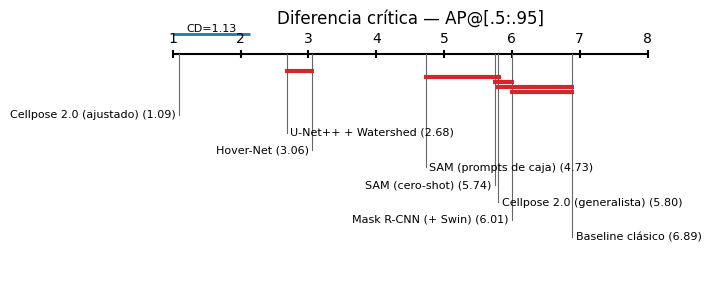

In [3]:
rep = pairwise_report(df, "ap", delta=DELTA)
if "friedman_p" in rep:
    print(f"Friedman χ² = {rep['friedman_stat']:.2f}, p = {rep['friedman_p']:.2e}; CD Nemenyi = {rep['cd_nemenyi']:.2f}")
    plot_cd_diagram(rep["mean_ranks"], rep["cd_nemenyi"], title="Diferencia crítica — AP@[.5:.95]")
    plt.savefig(FIG / "seg_cd_diagram.png", dpi=120, bbox_inches="tight")
rep["pairwise"].round(4)

In [4]:
try:
    mm = mixed_model_check(df.groupby(["modelo", "id_imagen", "sample_id"], as_index=False).ap.mean(),
                           score="ap", model="modelo", group="sample_id")
    print(mm.summary().tables[1])
except ImportError:
    print("statsmodels no instalado: `pip install statsmodels` para el modelo mixto")

                                         Coef. Std.Err.       z  P>|z|  \
Intercept                                0.004    0.010   0.383  0.702   
C(modelo)[T.Cellpose 2.0 (ajustado)]     0.226    0.011  20.518  0.000   
C(modelo)[T.Cellpose 2.0 (generalista)]  0.017    0.011   1.525  0.127   
C(modelo)[T.Hover-Net]                   0.136    0.011  12.332  0.000   
C(modelo)[T.Mask R-CNN (+ Swin)]         0.029    0.011   2.585  0.010   
C(modelo)[T.SAM (cero-shot)]             0.014    0.011   1.239  0.215   
C(modelo)[T.SAM (prompts de caja)]       0.060    0.011   5.468  0.000   
C(modelo)[T.U-Net++ + Watershed]         0.152    0.011  13.757  0.000   
Group Var                                0.003    0.008                  

                                         [0.025 0.975]  
Intercept                                -0.016  0.024  
C(modelo)[T.Cellpose 2.0 (ajustado)]      0.205  0.248  
C(modelo)[T.Cellpose 2.0 (generalista)]  -0.005  0.038  
C(modelo)[T.Hover-Net]         

/kaggle/working/proyecto-integrador/src/project/stats.py:228: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  return smf.mixedlm(f"{score} ~ C({model})", df, groups=df[group]).fit(reml=True)


## 3. Estratificación: tipo celular, densidad y tamaño (RQ1, H3)

/kaggle/working/proyecto-integrador/src/project/reporting.py:58: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return df.groupby([by, model])[metric].mean().unstack(model)


H3: APOYADA (el orden cambia al estratificar)


,estrato,orden,tau
0,global,Cellpose 2.0 (ajustado) > U-Net++ + Watershed ...,1.000000
1,astro,Cellpose 2.0 (ajustado) > Cellpose 2.0 (genera...,0.428571
2,cort,Cellpose 2.0 (ajustado) > U-Net++ + Watershed ...,0.928571
3,shsy5y,Cellpose 2.0 (ajustado) > U-Net++ + Watershed ...,0.785714


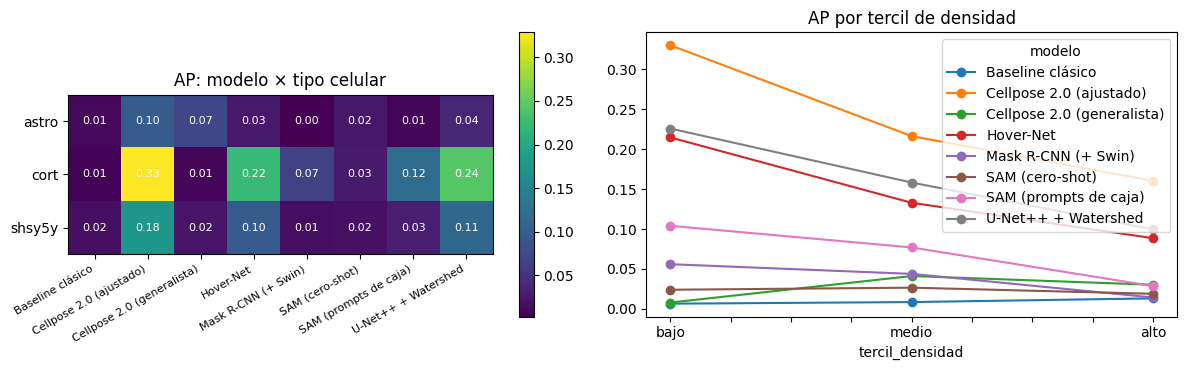

In [5]:
df = add_terciles(df, "densidad", "tercil_densidad")
heat = stratified(df, "ap", "tipo_celular")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
im = ax[0].imshow(heat.values, cmap="viridis"); ax[0].set_xticks(range(heat.shape[1])); ax[0].set_xticklabels(heat.columns, rotation=30, ha="right", fontsize=8)
ax[0].set_yticks(range(heat.shape[0])); ax[0].set_yticklabels(heat.index); plt.colorbar(im, ax=ax[0]); ax[0].set_title("AP: modelo × tipo celular")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax[0].text(j, i, f"{heat.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
stratified(df, "ap", "tercil_densidad").loc[["bajo", "medio", "alto"]].plot(ax=ax[1], marker="o")
ax[1].set_title("AP por tercil de densidad"); plt.tight_layout(); fig.savefig(FIG / "seg_estratificado.png", dpi=120)
h3 = simpson_check(df, "ap")
print("H3:", "REFUTADA (orden idéntico en los tres tipos)" if h3.iloc[1:].orden.nunique() == 1 and h3.iloc[1:].orden.iloc[0] == h3.orden.iloc[0]
      else "APOYADA (el orden cambia al estratificar)")
h3

## 4. Métricas de píxel vs instancia (RQ3, H2)

Spearman(rank AUC píxel, rank AP) = 0.69 [0.62, 0.76]; saturación AUC: False
H2: REFUTADA


Spearman(rank BA píxel, rank AP) = 0.64


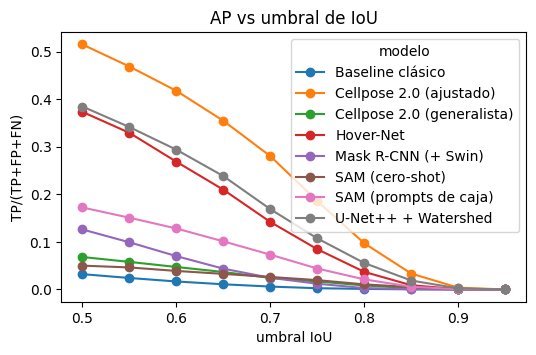

In [6]:
if "auc_roc" in df and df.auc_roc.notna().any():
    ag = ranking_agreement(df, "auc_roc", "ap")
    means = df.groupby("modelo").auc_roc.mean()
    sat = bool((means > 0.95).all() and (means.max() - means.min()) < 0.02)
    print(f"Spearman(rank AUC píxel, rank AP) = {ag['rho']:.2f} [{ag['ci_low']:.2f}, {ag['ci_high']:.2f}]; saturación AUC: {sat}")
    if np.isnan(ag["rho"]):
        print("H2: no evaluable (las medias de AUC no varían entre modelos; p. ej. mismo mapa de probabilidad)")
    else:
        print("H2:", "REFUTADA" if ag["rho"] > 0.9 or not (means > 0.95).all() else "APOYADA")
    ag_ba = ranking_agreement(df, "balanced_accuracy", "ap")
    print(f"Spearman(rank BA píxel, rank AP) = {ag_ba['rho']:.2f}")
# Curva AP vs umbral de IoU (columnas ap_t50 … ap_t95 de evaluate_image)
cols = [c for c in df.columns if c.startswith("ap_t")]
if cols:
    curve = df.groupby("modelo")[cols].mean().T; curve.index = [int(c[4:]) / 100 for c in cols]
    curve.plot(marker="o", title="AP vs umbral de IoU", xlabel="umbral IoU", ylabel="TP/(TP+FP+FN)", figsize=(6, 3.5))
    plt.savefig(FIG / "seg_ap_vs_iou.png", dpi=120, bbox_inches="tight")

## 5. Taxonomía de errores

Se clasifican automáticamente en omitida, falsa, fusión, división y desplazada (definiciones a priori en
`seg_metrics.error_taxonomy`). Las tasas se expresan por objeto de referencia, se desglosan por tipo
celular y se relacionan con la densidad.

/kaggle/working/proyecto-integrador/src/project/reporting.py:96: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  t = df.groupby(keys)[cols + ["n_gt"]].sum()


omitida_por_objeto  falsa_por_objeto  \
modelo                     tipo_celular                                         
Baseline clásico           astro                      0.382             0.578   
                           cort                       0.045            10.258   
                           shsy5y                     0.146             0.652   
Cellpose 2.0 (ajustado)    astro                      0.384             0.093   
                           cort                       0.143             0.101   
                           shsy5y                     0.192             0.038   
Cellpose 2.0 (generalista) astro                      0.604             0.038   
                           cort                       0.929             2.042   
                           shsy5y                     0.747             0.180   
Hover-Net                  astro                      0.073             0.342   
                           cort                       0.088             0.241   
                           shsy5y                     0.040             0.160   
Mask R-CNN (+ Swin)        astro                      0.771             0.091   
                           cort                       0.269             0.627   
                           shsy5y                     0.672             0.044   
SAM (cero-shot)            astro                      0.737             0.330   
                           cort                       0.690             2.357   
                           shsy5y                     0.867             0.316   
SAM (prompts de caja)      astro                      0.775             0.085   
                           cort                       0.268             0.565   
                           shsy5y                     0.683             0.059   
U-Net++ + Watershed        astro                      0.042             0.415   
                           cort                       0.157             0.145   
                           shsy5y                     0.041             0.228   

                                         fusion_por_objeto  \
modelo                     tipo_celular                      
Baseline clásico           astro                     0.040   
                           cort                      0.159   
                           shsy5y                    0.198   
Cellpose 2.0 (ajustado)    astro                     0.016   
                           cort                      0.047   
                           shsy5y                    0.150   
Cellpose 2.0 (generalista) astro                     0.065   
                           cort                      0.016   
                           shsy5y                    0.130   
Hover-Net                  astro                     0.018   
                           cort                      0.060   
                           shsy5y                    0.277   
Mask R-CNN (+ Swin)        astro                     0.001   
                           cort                      0.019   
                           shsy5y                    0.037   
SAM (cero-shot)            astro                     0.124   
                           cort                      0.070   
                           shsy5y                    0.058   
SAM (prompts de caja)      astro                     0.000   
                           cort                      0.024   
                           shsy5y                    0.048   
U-Net++ + Watershed        astro                     0.117   
                           cort                      0.040   
                           shsy5y                    0.265   

                                         division_por_objeto  \
modelo                     tipo_celular                        
Baseline clásico           astro                       0.327   
                           cort                        0.160   
                           shsy5y                      0.151   
C

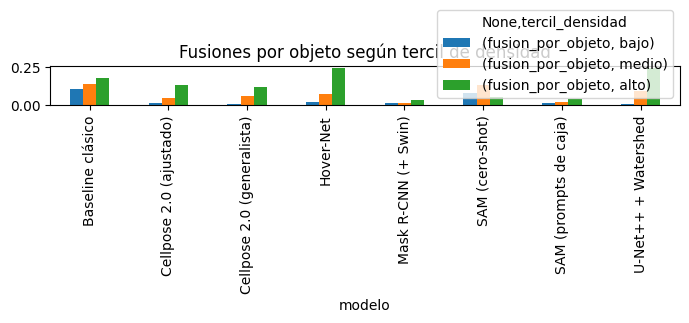

In [7]:
ep = error_profile(df)
ep_d = error_profile(df, by="tercil_densidad")
ep.to_csv(TAB / "seg_errores.csv")
ax = ep_d.unstack("tercil_densidad").filter(like="fusion").plot(kind="bar", figsize=(7, 3), title="Fusiones por objeto según tercil de densidad")
plt.tight_layout()
ep.round(3)

## 6. Conteo: utilidad práctica (Bland–Altman)

,mae,rmse,pearson_r,bias,loa_low,loa_high
Baseline clásico,226.06,261.61,0.60,226.06,-33.52,485.63
Cellpose 2.0 (ajustado),24.48,44.48,0.98,-22.34,-98.18,53.50
Cellpose 2.0 (generalista),86.60,123.58,0.39,-38.53,-270.03,192.96
Hover-Net,32.43,51.08,0.93,19.85,-72.94,112.64
Mask R-CNN (+ Swin),67.37,106.23,0.71,-41.42,-234.27,151.43
SAM (cero-shot),77.63,106.02,0.62,-23.72,-227.43,179.99
SAM (prompts de caja),64.27,105.64,0.75,-45.59,-233.46,142.27
U-Net++ + Watershed,30.26,46.34,0.95,21.05,-60.34,102.43


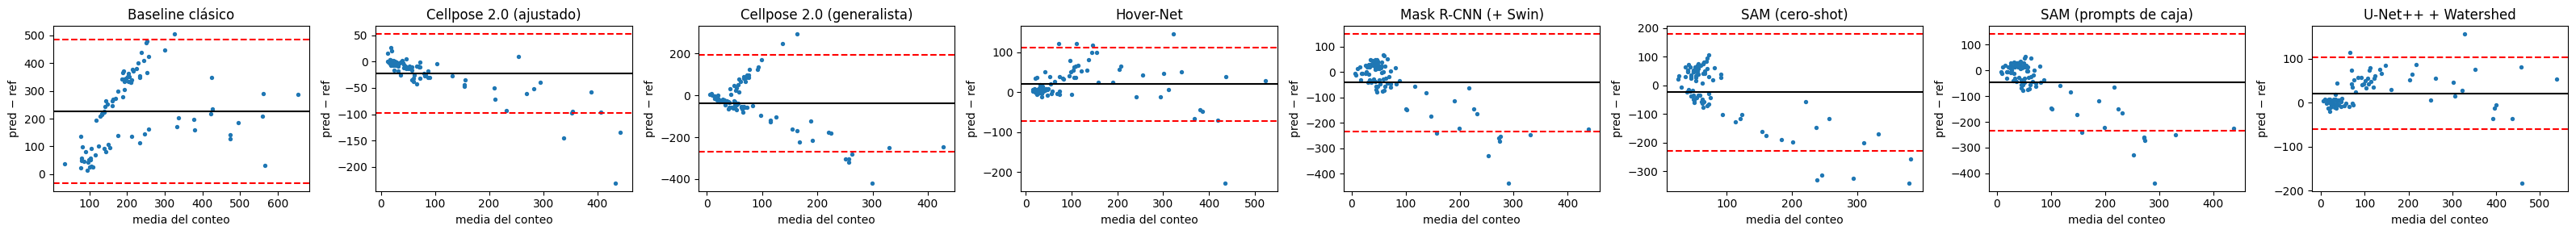

In [8]:
from project.seg_metrics import count_metrics
cm = pd.DataFrame({m: count_metrics(g.n_gt, g.n_pred) for m, g in df.groupby("modelo")}).T
fig, ax = plt.subplots(1, len(cm), figsize=(4 * len(cm), 3), squeeze=False)
for a, (m, g) in zip(ax[0], df.groupby("modelo")):
    mean, diff = (g.n_gt + g.n_pred) / 2, g.n_pred - g.n_gt
    a.scatter(mean, diff, s=8); a.axhline(diff.mean(), c="k"); a.axhline(cm.loc[m, "loa_low"], ls="--", c="r"); a.axhline(cm.loc[m, "loa_high"], ls="--", c="r")
    a.set(title=m, xlabel="media del conteo", ylabel="pred − ref")
plt.tight_layout()
cm.round(2)

## 7. Distribuciones y casos cualitativos

Se muestran un boxplot por métrica, una muestra aleatoria con semilla fija y los 5 mejores y 5 peores
casos (los IDs se guardan para las figuras de error del notebook 03).

aleatorias    [be85d2d45959, 3bcc8ba1dc17, 1d8ea1f865e0, 139...
mejores       [22e0c43da285, 56b8cad4f8e7, 23e6d1174f47, 97b...
peores        [3bcc8ba1dc17, eec79772cb99, 29dfe87f3a44, 5c8...
dtype: object

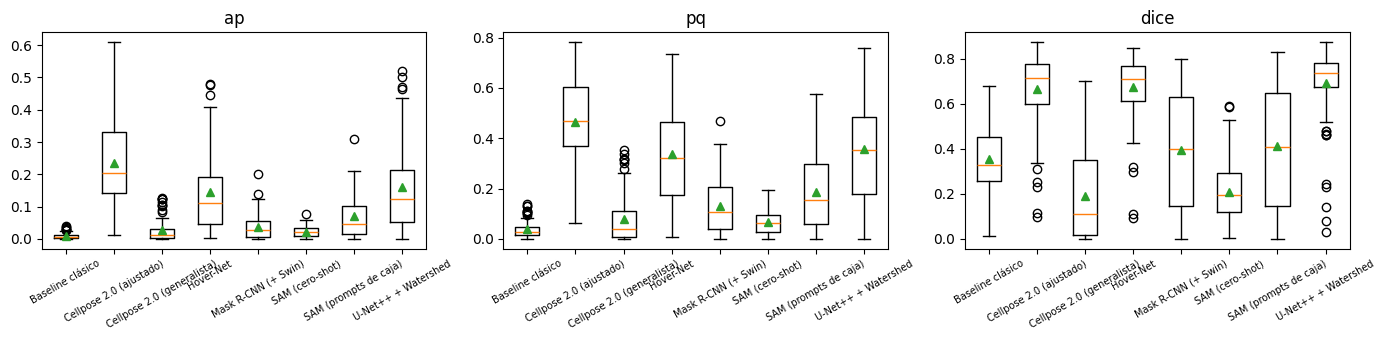

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, m in zip(ax, ["ap", "pq", "dice"]):
    a.boxplot([g[m].dropna() for _, g in df.groupby("modelo")], showmeans=True)
    a.set_xticks(range(1, df.modelo.nunique() + 1)); a.set_xticklabels(list(df.groupby("modelo").groups))
    a.set_title(m); a.tick_params(axis="x", rotation=30, labelsize=7)
plt.tight_layout(); fig.savefig(FIG / "seg_boxplots.png", dpi=120)
casos = best_worst(df, "ap"); pd.Series(casos)

## 8. Contraste de H1 (eficiencia de datos)

Usa `reports/tables/seg_fractions.csv` (`scripts/seg_experiments.py fractions`). Se calcula Δ25 y Δ100 por
imagen, (mejor preentrenado) − (U-Net++ desde cero), con IC bootstrap. Además se ajusta la ley de
potencia error(n) = a·n^(−b) + c.

In [10]:
FR = TAB / "seg_fractions.csv"
if FR.exists():
    from project.stats import fit_power_law
    fr = pd.read_csv(FR)
    for m, g in fr.groupby("modelo"):
        c = g.groupby("fraccion").ap.mean()
        print(m, "ley de potencia:", {k: round(v, 3) for k, v in fit_power_law(c.index.to_numpy() * 100, 1 - c.to_numpy()).items()})
    piv = fr.groupby(["fraccion", "id_imagen", "modelo"]).ap.mean().unstack()
    scratch = [c for c in piv.columns if "U-Net++" in c][0]
    pre = [c for c in piv.columns if c != scratch]
    best_pre = piv.loc[0.25, pre].mean().idxmax()
    d25 = (piv.loc[0.25, best_pre] - piv.loc[0.25, scratch]).dropna(); d100 = (piv.loc[1.0, best_pre] - piv.loc[1.0, scratch]).dropna()
    print("Δ25 =", fmt_ci(*bootstrap_ci(d25.to_numpy())), "| Δ100 =", fmt_ci(*bootstrap_ci(d100.to_numpy())),
          "| Δ25−Δ100 =", fmt_ci(*bootstrap_ci((d25 - d100).dropna().to_numpy())))
else:
    print("Pendiente: ejecutar `python scripts/seg_experiments.py fractions` (requiere datos y GPU).")

Cellpose 2.0 (ajustado) ley de potencia: {'a': 0.165, 'b': 0.442, 'c': 0.742, 'se_b': nan}
U-Net++ + Watershed ley de potencia: {'a': 1.54, 'b': 0.477, 'c': 0.667, 'se_b': nan}
Δ25 = 0.218 [0.188, 0.247] | Δ100 = 0.075 [0.065, 0.085] | Δ25−Δ100 = 0.142 [0.115, 0.171]


/kaggle/working/proyecto-integrador/src/project/stats.py:287: OptimizeWarning: Covariance of the parameters could not be estimated
  (a, b, c), cov = curve_fit(f, n, err, p0=p0, bounds=([0, 0, 0], [np.inf, 5, 1]), maxfev=20_000)


## 9. HPO: importancia de hiperparámetros y dependencia parcial

In [11]:
HP = TAB / "seg_hpo_trials.csv"
if HP.exists():
    tr = pd.read_csv(HP)
    pcols = [c for c in tr.columns if c.startswith("params_")]
    fig, ax = plt.subplots(1, len(pcols), figsize=(3 * len(pcols), 2.8))
    for a, c in zip(np.atleast_1d(ax), pcols):
        tr.groupby(c)["value"].mean().plot(ax=a, marker="o"); a.set_title(c.replace("params_", ""), fontsize=8)
    plt.tight_layout()
    imp = TAB / "seg_hpo_importance.json"
    print(imp.read_text() if imp.exists() else "")
else:
    print("Pendiente: `python scripts/seg_experiments.py hpo --trials 30`.")

Pendiente: `python scripts/seg_experiments.py hpo --trials 30`.
